# CredAIR — Análise de Risco de Crédito

**Objetivo:** usar o histórico de propostas de crédito da CredAIR para entender os fatores ligados à inadimplência e construir um modelo de **Regressão Logística** que identifique propostas de maior risco.

## 0. Configuração do ambiente

Importamos as bibliotecas e fixamos uma **semente aleatória** (`RANDOM_STATE`). Com ela, a divisão treino/teste e o treinamento produzem sempre os mesmos resultados.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Semente aleatória: garante resultados reprodutíveis
RANDOM_STATE = 42

# Caminhos das camadas (o notebook roda dentro de notebooks/, então a raiz fica um nível acima)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRONZE = RAIZ / "data" / "bronze" / "dataset.csv"
PRATA = RAIZ / "data" / "silver" / "credito_limpo.parquet"
OURO = RAIZ / "data" / "gold" / "credito_modelagem.parquet"
FIGURAS = RAIZ / "reports" / "figures"

# Estilo dos gráficos: fundo limpo e duas cores fixas para as classes
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
CORES_CLASSE = {0: AZUL, 1: LARANJA}
sns.set_theme(style="whitegrid", rc={"grid.color": "#e1e0d9", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)


def salvar(fig, nome):
    # Salva a figura em reports/figures para usar na apresentação
    fig.savefig(FIGURAS / f"{nome}.png", dpi=120, bbox_inches="tight")


print("Bronze encontrada:", BRONZE.exists())


Bronze encontrada: True


## 1. Entendimento do problema

### 1.1 Carregando os dados brutos (camada bronze)

Lemos o arquivo **exatamente como foi recebido**. Nenhuma alteração é feita nesta etapa.


In [2]:
bronze = pd.read_csv(BRONZE)
print(f"Linhas: {bronze.shape[0]:,} | Colunas: {bronze.shape[1]}")
bronze.head()


Linhas: 5,000 | Colunas: 11


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,"2,911.820",14,690,"5,934.190",60,Viagem,1,0
1,49,RR,Ensino Médio,"3,176.430",5,676,"6,791.380",24,Outros,2,0
2,48,AL,Ensino Superior,"3,429.400",23,558,"14,666.780",24,Outros,5,1
3,59,GO,Ensino Fundamental,"10,096.700",2,739,"19,053.240",24,Reforma,0,0
4,37,RJ,Ensino Fundamental,"3,033.250",24,797,"6,171.310",6,Educação,0,1


### 1.2 Variável resposta e tipo de problema

- **Variável resposta:** `inadimplente`. Vale `1` quando a proposta resultou em falta de pagamento e `0` quando não.
- **Tipo de problema:** **classificação binária supervisionada**. É *supervisionada* porque temos o resultado histórico de cada proposta, e *binária* porque a resposta tem duas classes.


In [3]:
contagem = bronze["inadimplente"].value_counts().sort_index()
pd.DataFrame({
    "quantidade": contagem,
    "proporção": (contagem / contagem.sum()).map("{:.1%}".format),
}).rename(index={0: "0 - adimplente", 1: "1 - inadimplente"})


,quantidade,proporção
inadimplente,,
0 - adimplente,3280,65.6%
1 - inadimplente,1720,34.4%


**Primeira leitura:** cerca de **34%** das propostas resultaram em inadimplência. As classes são **moderadamente desbalanceadas**. Um "modelo" que dissesse sempre "adimplente" acertaria cerca de 66% dos casos **sem identificar nenhum inadimplente**. Por isso a **acurácia não é uma boa métrica** aqui: usaremos ROC-AUC e recall.


## 2. Diagnóstico de qualidade dos dados

Antes de corrigir qualquer coisa, fazemos um **inventário dos problemas**.

> 🧭 **Decisão: diagnosticar antes de tratar.** Separar as duas etapas evita "consertar" um problema e esconder outro.

### 2.1 Tipos e valores nulos


In [4]:
pd.DataFrame({
    "tipo": bronze.dtypes.astype(str),
    "nulos": bronze.isna().sum(),
    "valores_distintos": bronze.nunique(),
})


,tipo,nulos,valores_distintos
idade,int64,0,73
estado,str,0,85
escolaridade,str,0,4
renda_mensal,float64,0,4921
tempo_emprego_anos,int64,0,32
score_credito,int64,0,428
valor_solicitado,float64,0,4937
prazo_meses,int64,0,7
finalidade,str,0,6
dividas_ativas,int64,0,8


**Leitura da tabela:**
- **Não há valores nulos explícitos.** Isso não garante que os dados estejam corretos: um problema pode aparecer como **valor inválido** em vez de vazio (verificado na seção 2.2).
- ⚠️ **`estado` tem 85 valores distintos, mas o Brasil tem só 27 UFs.** Hipótese: variações de escrita da mesma UF, como `"MG"`, `" MG"` e `"MG "`. Para o computador, são categorias diferentes. Confirmado na seção 2.4.
- `escolaridade` (4) e `finalidade` (6) têm poucas categorias, como esperado. `prazo_meses` tem só 7 valores, então funciona quase como uma categoria.
- `renda_mensal` e `valor_solicitado` têm quase um valor distinto por linha, o esperado para valores com centavos. Por isso, duas linhas idênticas até nos centavos dificilmente são coincidência (verificado na seção 2.3).
- As colunas de texto (`estado`, `escolaridade` e `finalidade`) serão convertidas para **categoria** na limpeza.


### 2.2 Estatísticas descritivas


In [6]:
bronze.describe().T


,count,mean,std,min,25%,50%,75%,max
idade,"5,000.000",47.767,31.646,18.000,32.000,46.000,61.000,750.000
renda_mensal,"5,000.000","5,228.634","3,968.478",100.000,"2,697.320","4,146.300","6,458.877","44,814.190"
tempo_emprego_anos,"5,000.000",12.662,7.518,1.000,6.000,13.000,19.000,74.000
score_credito,"5,000.000",652.481,84.817,335.000,594.000,653.000,710.000,850.000
valor_solicitado,"5,000.000","14,264.657","8,268.261","1,721.480","8,467.170","12,365.630","17,764.885","50,000.000"
prazo_meses,"5,000.000",29.922,15.483,6.000,18.000,24.000,36.000,60.000
dividas_ativas,"5,000.000",1.900,1.865,0.000,0.000,1.000,3.000,7.000
inadimplente,"5,000.000",0.344,0.475,0.000,0.000,0.000,1.000,1.000


Alguns sinais aparecem já na tabela:
- `idade` chega a **750 anos**.
- `tempo_emprego_anos` chega a **74 anos**.
- `renda_mensal` tem mínimo de **R$ 100**.

Não há nulos explícitos, mas um problema pode aparecer como **valor inválido** em vez de vazio.


### 2.3 Duplicidades


In [7]:
n_dup = bronze.duplicated().sum()
print(f"Linhas duplicadas (idênticas em todas as colunas): {n_dup}")
bronze[bronze.duplicated(keep=False)].sort_values(list(bronze.columns)).head(6)


Linhas duplicadas (idênticas em todas as colunas): 19


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
813,20,RN,Ensino Superior,"7,393.680",13,826,"20,006.350",36,Reforma,2,0
3723,20,RN,Ensino Superior,"7,393.680",13,826,"20,006.350",36,Reforma,2,0
2748,23,SC,Ensino Médio,"5,657.970",3,718,"6,468.510",36,Reforma,1,0
4726,23,SC,Ensino Médio,"5,657.970",3,718,"6,468.510",36,Reforma,1,0
2177,25,AC,Ensino Médio,"4,663.760",10,715,"12,020.380",36,Veículo,0,0
3089,25,AC,Ensino Médio,"4,663.760",10,715,"12,020.380",36,Veículo,0,0


**Leitura:** há **19 linhas idênticas em todas as 11 colunas**, inclusive renda e valor com centavos. Pela tabela 2.1, esses valores quase nunca se repetem, então a chance de duas propostas diferentes coincidirem em tudo é praticamente nula. Isso indica **registro duplicado**: as cópias estão espalhadas pela base (ex.: linhas 813 e 3723), o que é compatível com uma proposta que entrou duas vezes no sistema.

**Por que tratar:** uma duplicata pesa em dobro no treino e, se uma cópia cair no treino e outra no teste, o modelo é avaliado num exemplo que já viu (**vazamento de dados**).
**Tratamento proposto (seção 3):** remover as cópias, mantendo a primeira ocorrência.


### 2.4 Categorias com espaços extras


In [8]:
for col in ["estado", "escolaridade", "finalidade"]:
    valores = bronze[col]
    com_espaco = (valores != valores.str.strip()).sum()
    print(f"{col:13s} | categorias distintas: {valores.nunique():3d} | "
          f"após remover espaços: {valores.str.strip().nunique():3d} | registros com espaços: {com_espaco}")

print("\nExemplos:", bronze.loc[bronze["estado"] != bronze["estado"].str.strip(), "estado"].map(repr).unique()[:6])


estado        | categorias distintas:  85 | após remover espaços:  27 | registros com espaços: 101
escolaridade  | categorias distintas:   4 | após remover espaços:   4 | registros com espaços: 0
finalidade    | categorias distintas:   6 | após remover espaços:   6 | registros com espaços: 0

Exemplos: <ArrowStringArray>
['' DF '', '' PA '', '' BA '', '' PI '', ''  CE '', '' AM  '']
Length: 6, dtype: str


**Leitura:** ✅ hipótese da seção 2.1 confirmada. `estado` cai de **85 para 27 categorias** ao remover os espaços: os 58 "estados" a mais eram variações como `' DF '` e `'  CE '`, em **101 registros**. `escolaridade` e `finalidade` não têm o problema.

**Tratamento proposto (seção 3):** remover espaços e padronizar em maiúsculas. Isso deve ser feito **antes** de remover as duplicatas, porque duas linhas que só diferem no espaço do estado também são cópias.


### 2.5 Valores inválidos e inconsistências

Cada regra de negócio vira um teste. Contamos quantos registros violam cada uma.


In [10]:
idade_valida = bronze["idade"].between(18, 100)

regras = {
    "idade fora de 18–100 anos": ~idade_valida,
    "tempo de emprego ≥ idade": bronze["tempo_emprego_anos"] >= bronze["idade"],
    "começou a trabalhar antes dos 14 anos (idade válida)":
        idade_valida & (bronze["tempo_emprego_anos"] > bronze["idade"] - 14),
    "renda mensal < R$ 600": bronze["renda_mensal"] < 600,
    "score fora de 0–1000": ~bronze["score_credito"].between(0, 1000),
    "valor solicitado ≤ 0": bronze["valor_solicitado"] <= 0,
    "dívidas ativas < 0": bronze["dividas_ativas"] < 0,
}
pd.DataFrame({"registros": {k: int(v.sum()) for k, v in regras.items()}})


,registros
idade fora de 18–100 anos,15
tempo de emprego ≥ idade,8
começou a trabalhar antes dos 14 anos (idade válida),696
renda mensal < R$ 600,10
score fora de 0–1000,0
valor solicitado ≤ 0,0
dívidas ativas < 0,0


**Leitura:**
- **Impossíveis (erro certo):** 15 idades fora de 18–100 anos e 8 casos de tempo de emprego ≥ idade.
- **Suspeitos:** 10 rendas abaixo de R$ 600.
- **Plausíveis, mas incomuns:** 696 casos (14% da base) de início de trabalho antes dos 14 anos. O volume é alto demais para tratar sem investigar.
- ✅ Score, valor solicitado e dívidas ativas passaram em todas as verificações.


In [11]:
print("Idades fora do intervalo:", sorted(bronze.loc[~idade_valida, "idade"]))
print("Rendas abaixo de R$ 600:  ", sorted(bronze.loc[bronze["renda_mensal"] < 600, "renda_mensal"]))

Idades fora do intervalo: [210, 280, 300, 340, 360, 430, 440, 500, 540, 660, 670, 680, 700, 710, 750]
Rendas abaixo de R$ 600:   [100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0, 550.0]


**Leitura:**
- **Idades:** todas as 15 inválidas são **múltiplas de 10** (210 a 750). Dividir por 10 daria idades plausíveis (21 a 75), sugerindo um zero digitado a mais. Testamos essa correção: 14 casos ficam coerentes, mas 1 passa a indicar início de trabalho aos 11 anos. Como a correção é uma **suposição não verificável** e o volume é pequeno (0,3%), optamos por **marcar como ausente** e imputar no pipeline.
- **Rendas:** as 10 rendas abaixo de R$ 600 formam uma **sequência exata** de R$ 100 a R$ 550, de 50 em 50, um registro de cada. Isso não ocorre naturalmente: são **valores artificiais**. Tratamento: **marcar como ausente**.


#### Investigação: início de trabalho antes dos 14 anos


In [12]:
# Onde estão os casos de "começou a trabalhar antes dos 14 anos"?
inconsistente = regras["começou a trabalhar antes dos 14 anos (idade válida)"]
faixa = pd.cut(bronze["idade"], [17, 25, 35, 45, 100], labels=["18–25", "26–35", "36–45", "46+"])
pd.DataFrame({
    "casos": inconsistente.groupby(faixa, observed=True).sum(),
    "% da faixa": inconsistente.groupby(faixa, observed=True).mean().map("{:.0%}".format),
})


,casos,% da faixa
idade,,
18–25,351,50%
26–35,314,36%
36–45,25,3%
46+,6,0%


**Leitura:** o problema está **concentrado nos jovens**: atinge 50% das pessoas de 18 a 25 anos e 36% das de 26 a 35, mas é raro acima dos 36.

> 🧭 **Decisão: manter esses casos (P6).** São cerca de 690 registros (14% da base). Removê-los ou anulá-los **enviesaria a base contra os jovens**, e o modelo funcionaria pior justamente para esse grupo. Há explicações plausíveis (aprendiz, trabalho informal ou familiar), então o caso é **incomum, não impossível**. Fica registrado como **limitação** da análise.


### 2.6 Resumo do diagnóstico

| # | Problema | Registros | Evidência | Tratamento proposto (seção 3) |
|---|---|---|---|---|
| P1 | Espaços extras em `estado` | 101 | 85 categorias → 27 após remover espaços | Remover espaços e padronizar em maiúsculas |
| P2 | Linhas duplicadas | 19 | Idênticas nas 11 colunas, inclusive centavos | Remover cópias (depois do P1) |
| P3 | Idade fora de 18–100 anos | 15 | 210 a 750, todas múltiplas de 10 | Marcar como ausente |
| P4 | Tempo de emprego ≥ idade | 8 | Impossível | Marcar como ausente |
| P5 | Renda abaixo de R$ 600 | 10 | Sequência exata de R$ 100 a R$ 550 | Marcar como ausente |
| P6 | Início de trabalho antes dos 14 anos | 696 | Concentrado em 18–35 anos | **Manter** e registrar como limitação |

**Por que "marcar como ausente" em vez de remover a linha?** As outras 10 colunas da linha estão corretas. Apagar a linha inteira jogaria fora informação boa por causa de um único campo errado.


## 3. Limpeza e preparação dos dados (bronze → 🥈 prata)

Toda a limpeza fica numa **única função**, `limpar`, que aplica as regras P1 a P5 do diagnóstico (seção 2.6) e devolve os dados limpos e um **log** com quantos registros cada regra afetou.


In [13]:
ORDEM_ESCOLARIDADE = ["Ensino Fundamental", "Ensino Médio", "Ensino Superior", "Pós-graduação"]


def limpar(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Aplica as regras de limpeza e devolve (dados_limpos, log_de_tratamentos)
    df = df.copy()
    log = []

    # P1 — padroniza a UF: remove espaços e usa maiúsculas
    afetados = (df["estado"] != df["estado"].str.strip().str.upper()).sum()
    df["estado"] = df["estado"].str.strip().str.upper()
    log.append(("P1", "Espaços removidos em estado", afetados))

    # P2 — remove duplicatas (depois de padronizar, para pegar duplicatas "disfarçadas")
    antes = len(df)
    df = df.drop_duplicates(keep="first").reset_index(drop=True)
    log.append(("P2", "Linhas duplicadas removidas", antes - len(df)))

    # P3 — idade fora do intervalo plausível vira ausente
    invalida = ~df["idade"].between(18, 100)
    df["idade"] = df["idade"].astype("float").mask(invalida)
    log.append(("P3", "Idade inválida → ausente", int(invalida.sum())))

    # P4 — tempo de emprego maior ou igual à idade vira ausente
    invalido = df["tempo_emprego_anos"] >= df["idade"]
    df["tempo_emprego_anos"] = df["tempo_emprego_anos"].astype("float").mask(invalido)
    log.append(("P4", "Tempo de emprego ≥ idade → ausente", int(invalido.sum())))

    # P5 — renda abaixo de R$ 600 (sequência artificial) vira ausente
    invalida = df["renda_mensal"] < 600
    df["renda_mensal"] = df["renda_mensal"].mask(invalida)
    log.append(("P5", "Renda < R$ 600 → ausente", int(invalida.sum())))

    # Tipos: categorias explícitas (escolaridade é ordinal)
    df["escolaridade"] = pd.Categorical(df["escolaridade"], categories=ORDEM_ESCOLARIDADE, ordered=True)
    df["estado"] = df["estado"].astype("category")
    df["finalidade"] = df["finalidade"].astype("category")
    df["inadimplente"] = df["inadimplente"].astype("int8")

    return df, pd.DataFrame(log, columns=["problema", "tratamento", "registros"])


In [14]:
prata, log_limpeza = limpar(bronze)
log_limpeza


,problema,tratamento,registros
0,P1,Espaços removidos em estado,101
1,P2,Linhas duplicadas removidas,19
2,P3,Idade inválida → ausente,15
3,P4,Tempo de emprego ≥ idade → ausente,8
4,P5,Renda < R$ 600 → ausente,10


### 3.1 Conferência: antes e depois

Tratamento sem verificação é só esperança. Conferimos se cada regra foi de fato aplicada.


In [15]:
checagens = {
    "linhas": (len(bronze), len(prata)),
    "duplicatas": (bronze.duplicated().sum(), prata.duplicated().sum()),
    "UFs distintas": (bronze["estado"].nunique(), prata["estado"].nunique()),
    "idade máxima": (bronze["idade"].max(), prata["idade"].max()),
    "tempo de emprego máximo": (bronze["tempo_emprego_anos"].max(), prata["tempo_emprego_anos"].max()),
    "renda mínima": (bronze["renda_mensal"].min(), prata["renda_mensal"].min()),
    "taxa de inadimplência": (f"{bronze['inadimplente'].mean():.1%}", f"{prata['inadimplente'].mean():.1%}"),
}
pd.DataFrame(checagens, index=["bronze", "prata"]).T


,bronze,prata
linhas,5000,4981
duplicatas,19,0
UFs distintas,85,27
idade máxima,750.000,75.000
tempo de emprego máximo,74.000,25.000
renda mínima,100.000,900.000
taxa de inadimplência,34.4%,34.4%


**Leitura:** todas as regras foram aplicadas como planejado. Saíram apenas as 19 duplicatas (5.000 → 4.981 linhas); os problemas P3 a P5 viraram ausentes **sem apagar linhas**. As UFs caíram para 27 e os extremos de idade, tempo de emprego e renda ficaram plausíveis. A **taxa de inadimplência não mudou (34,4%)**: a limpeza não distorceu o fenômeno estudado.


In [17]:
print("Valores ausentes na camada prata (serão imputados no pipeline, seção 6):")
ausentes = prata.isna().sum()
ausentes[ausentes > 0]


Valores ausentes na camada prata (serão imputados no pipeline, seção 6):


idade                 15
renda_mensal          10
tempo_emprego_anos     8
dtype: int64

In [18]:
PRATA.parent.mkdir(parents=True, exist_ok=True)
prata.to_parquet(PRATA, index=False)
print(f"Camada prata salva em {PRATA.relative_to(RAIZ)}: {prata.shape[0]:,} linhas × {prata.shape[1]} colunas")


Camada prata salva em data\silver\credito_limpo.parquet: 4,981 linhas × 11 colunas


## 4. Análise exploratória (camada 🥈 prata)

A análise exploratória vem **depois** da limpeza: uma idade de 750 anos distorceria qualquer gráfico. A pergunta que guia esta seção é: **quais características separam adimplentes de inadimplentes?**

### 4.1 Distribuição da variável resposta


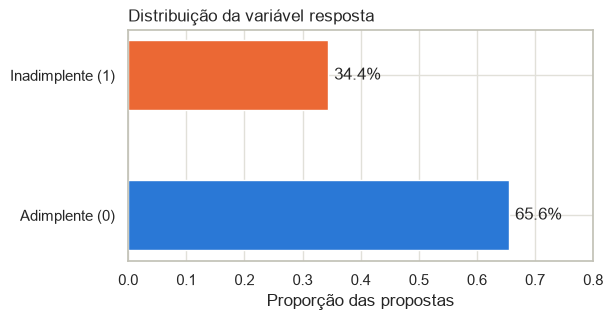

In [19]:
fig, ax = plt.subplots(figsize=(6, 3))
taxa = prata["inadimplente"].value_counts(normalize=True).sort_index()
ax.barh(["Adimplente (0)", "Inadimplente (1)"], taxa.values, color=[AZUL, LARANJA], height=0.5)
for i, v in enumerate(taxa.values):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
ax.set_xlim(0, 0.8)
ax.set_xlabel("Proporção das propostas")
ax.set_title("Distribuição da variável resposta", loc="left")
salvar(fig, "01_distribuicao_alvo")
plt.show()


### 4.2 Variáveis numéricas: distribuição por classe

Comparamos a distribuição de cada variável entre adimplentes e inadimplentes. Quanto mais as caixas se **deslocam** uma em relação à outra, mais a variável ajuda a separar as classes.


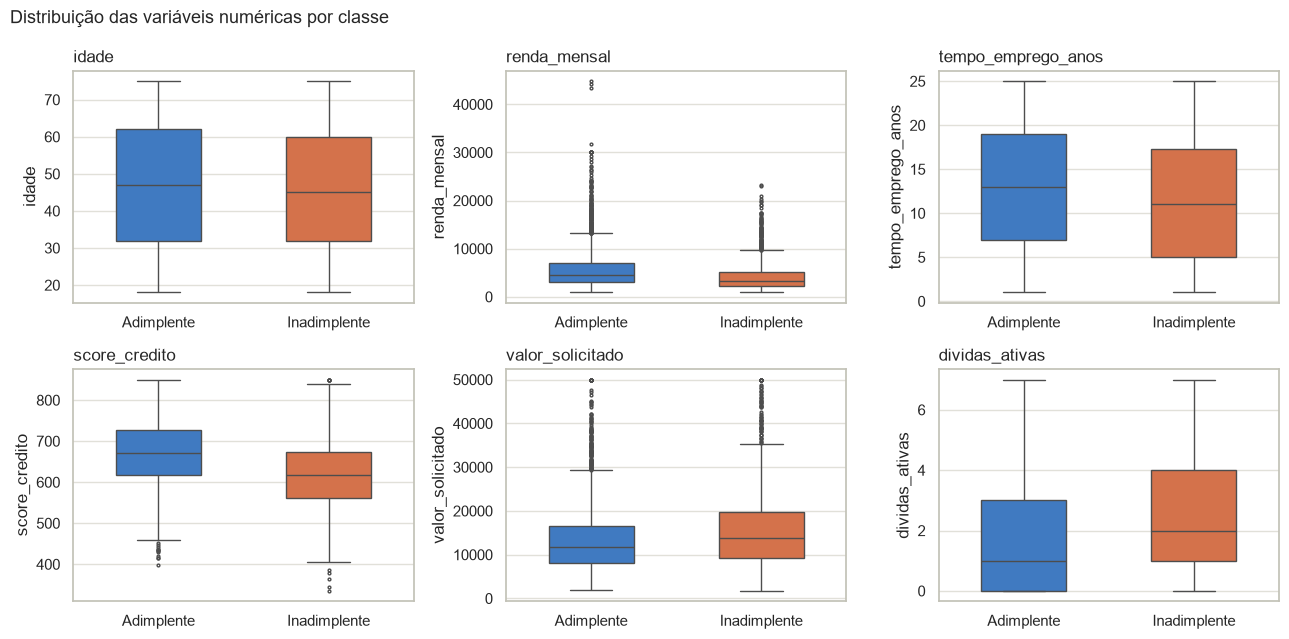

In [20]:
numericas = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito", "valor_solicitado", "dividas_ativas"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, numericas):
    sns.boxplot(data=prata, x="inadimplente", y=col, hue="inadimplente", palette=CORES_CLASSE,
                legend=False, ax=ax, width=0.5, fliersize=2)
    ax.set_xticks([0, 1], ["Adimplente", "Inadimplente"])
    ax.set_xlabel("")
    ax.set_title(col, loc="left")
fig.suptitle("Distribuição das variáveis numéricas por classe", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
salvar(fig, "02_boxplots_numericas")
plt.show()


**Leitura:** três variáveis mostram deslocamento claro entre as classes:
- **`dividas_ativas`**: inadimplentes têm mais dívidas em aberto.
- **`score_credito`**: inadimplentes têm score mais baixo.
- **`renda_mensal`**: inadimplentes têm renda mais baixa.

Em `idade`, `tempo_emprego_anos` e `valor_solicitado`, as caixas ficam próximas: a separação, se existir, é fraca. *Ressalva:* o gráfico mostra **associação**, não causalidade.


### 4.3 Taxa de inadimplência por faixa

O boxplot mostra a distribuição. Para o negócio, porém, a pergunta mais direta é: **em cada faixa, qual a taxa de inadimplência?** Dividimos cada variável em 5 faixas com a mesma quantidade de propostas (quintis).


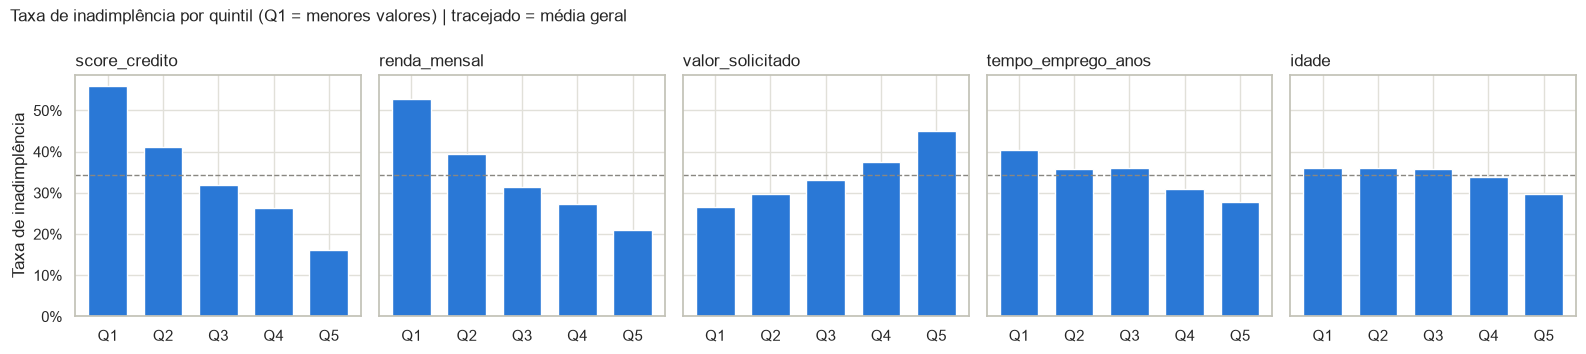

In [30]:
taxa_geral = prata["inadimplente"].mean()
continuas = ["score_credito", "renda_mensal", "valor_solicitado", "tempo_emprego_anos", "idade"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
for ax, col in zip(axes, continuas):
    faixas = pd.qcut(prata[col], 5, duplicates="drop")
    t = prata.groupby(faixas, observed=True)["inadimplente"].mean()
    ax.bar(range(len(t)), t.values, color=AZUL, width=0.7)
    ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
    ax.set_xticks(range(len(t)), [f"Q{i+1}" for i in range(len(t))])
    ax.set_title(col, loc="left")
axes[0].set_ylabel("Taxa de inadimplência")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Taxa de inadimplência por quintil (Q1 = menores valores) | tracejado = média geral",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
salvar(fig, "03_taxa_por_quintil")
plt.show()


In [31]:
# Valores do gráfico 4.3: taxa de inadimplência por quintil
tabela_quintis = pd.DataFrame({
    col: prata.groupby(pd.qcut(prata[col], 5, duplicates="drop"), observed=True)["inadimplente"].mean().values
    for col in continuas
}, index=["Q1", "Q2", "Q3", "Q4", "Q5"]).T

tabela_quintis.map("{:.0%}".format)


,Q1,Q2,Q3,Q4,Q5
score_credito,56%,41%,32%,26%,16%
renda_mensal,53%,39%,31%,27%,21%
valor_solicitado,27%,30%,33%,37%,45%
tempo_emprego_anos,40%,36%,36%,31%,28%
idade,36%,36%,36%,34%,30%


**Leitura:**
- **Score** é o sinal mais forte: a inadimplência cai de **56%** no quintil de menor score para **16%** no de maior.
- **Renda**: de **53%** para **21%**.
- **Valor solicitado**: sobe de 27% para **45%**. No boxplot o efeito parecia pequeno, mas por faixa ele fica evidente.
- **Tempo de emprego** (40% → 28%) tem efeito moderado; **idade** (36% → 30%) quase não muda.


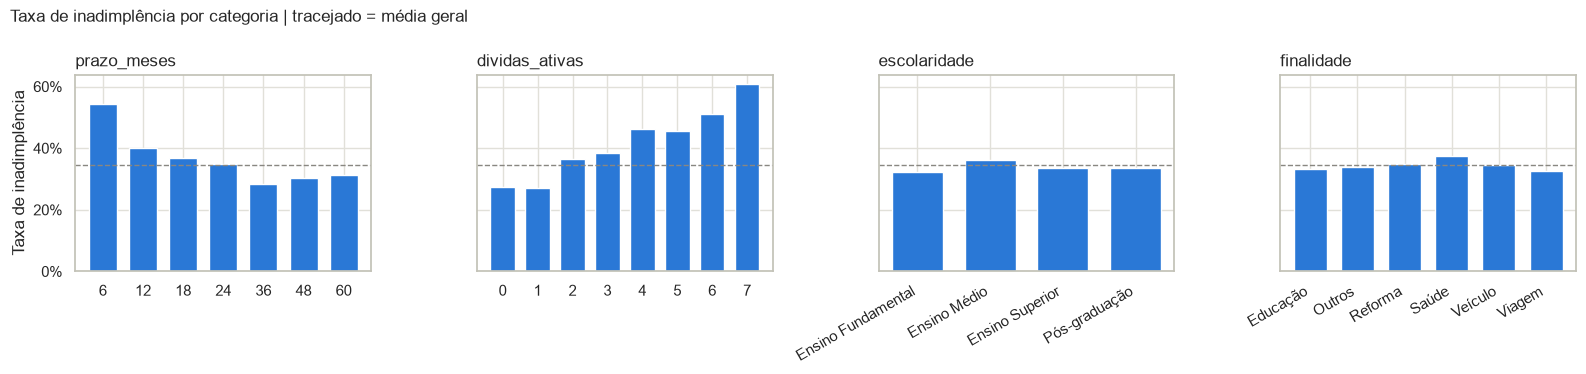

In [32]:
discretas = ["prazo_meses", "dividas_ativas", "escolaridade", "finalidade"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, discretas):
    t = prata.groupby(col, observed=True)["inadimplente"].mean()
    ax.bar(range(len(t)), t.values, color=AZUL, width=0.7)
    ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
    ax.set_xticks(range(len(t)), [str(i) for i in t.index], rotation=30 if col in ("escolaridade", "finalidade") else 0,
                  ha="right" if col in ("escolaridade", "finalidade") else "center")
    ax.set_title(col, loc="left")
axes[0].set_ylabel("Taxa de inadimplência")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.suptitle("Taxa de inadimplência por categoria | tracejado = média geral", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
salvar(fig, "04_taxa_por_categoria")
plt.show()


In [33]:
# Valores do gráfico 4.4: taxa de inadimplência por categoria
tabela_categorias = pd.concat({
    col: prata.groupby(col, observed=True)["inadimplente"].agg(propostas="size", taxa="mean")
    for col in discretas
}, names=["variável", "categoria"])

tabela_categorias["taxa"] = tabela_categorias["taxa"].map("{:.0%}".format)
tabela_categorias


propostas taxa
variável       categoria                         
prazo_meses    6                         292  54%
               12                        688  40%
               18                        649  37%
               24                       1010  35%
               36                       1262  28%
               48                        597  30%
               60                        483  31%
dividas_ativas 0                        1551  27%
               1                         958  27%
               2                         844  36%
               3                         630  39%
               4                         420  46%
               5                         319  45%
               6                         162  51%
               7                          97  61%
escolaridade   Ensino Fundamental        410  32%
               Ensino Médio             2050  36%
               Ensino Superior          1932  33%
               Pós-graduação             589  34%
finalidade     Educação                  706  33%
               Outros                    939  34%
               Reforma                  1112  35%
               Saúde                     608  38%
               Veículo                  1123  34%
               Viagem                    493  32%

**Leitura:**
- **Prazo:** quanto **menor** o prazo, **maior** a inadimplência: **54%** em 6 meses contra 28% em 36 meses. É um resultado contraintuitivo. **Hipótese:** com o mesmo valor, um prazo curto gera uma **parcela mais pesada** em relação à renda. Testaremos essa hipótese criando uma variável na seção 5.
- **Dívidas ativas:** o risco sobe de **27%** (0 dívidas) para **61%** (7 dívidas). Mais compromissos disputam a mesma renda.
- **Escolaridade** (32%–36%) e **finalidade** (32%–38%) ficam próximas da média geral. As diferenças podem ser **acaso**, o que verificamos na seção 4.4.


### 4.4 Diferença real ou acaso? (teste qui-quadrado)

Com 27 UFs e cerca de 185 propostas em cada uma, é natural que as taxas variem um pouco **só por acaso**. Usamos o **teste qui-quadrado de independência** para saber se as diferenças entre categorias são grandes demais para serem acaso.


In [34]:
from scipy.stats import chi2_contingency

resultado = []
for col in ["estado", "escolaridade", "finalidade", "prazo_meses", "dividas_ativas"]:
    tabela = pd.crosstab(prata[col], prata["inadimplente"])
    chi2, p, gl, _ = chi2_contingency(tabela)
    t = prata.groupby(col, observed=True)["inadimplente"].mean()
    resultado.append({"variável": col, "categorias": len(tabela), "menor taxa": f"{t.min():.1%}",
                      "maior taxa": f"{t.max():.1%}", "p-valor": p,
                      "associação significativa (5%)?": "sim" if p < 0.05 else "não"})
tabela_qui2 = pd.DataFrame(resultado).set_index("variável")
tabela_qui2["p-valor"] = tabela_qui2["p-valor"].map(lambda p: "< 0.0001" if p < 0.0001 else f"{p:.2f}")
tabela_qui2


,categorias,menor taxa,maior taxa,p-valor,associação significativa (5%)?
variável,,,,,
estado,27,29.4%,42.2%,0.60,não
escolaridade,4,32.2%,36.0%,0.23,não
finalidade,6,32.5%,37.5%,0.54,não
prazo_meses,7,28.4%,54.5%,< 0.0001,sim
dividas_ativas,8,26.9%,60.8%,< 0.0001,sim


**Como ler o p-valor:** é a probabilidade de observar diferenças tão grandes quanto essas **se, na verdade, a variável não tivesse relação nenhuma** com a inadimplência. Um p-valor abaixo de 5% indica que a diferença dificilmente é acaso.

**Leitura:**
- **Prazo** e **dívidas ativas**: associação **significativa** (p < 0,0001).
- **Escolaridade** (p = 0,23) e **finalidade** (p = 0,54): **sem associação significativa**. As pequenas diferenças são compatíveis com o acaso.
- ⚠️ **Estado** (p = 0,60): a diferença entre a menor (29%) e a maior taxa (42%) **parece grande, mas é compatível com o acaso**. Com 27 UFs e cerca de 185 propostas em cada, é esperado que algumas fiquem longe da média. Além de não haver evidência, usar a região para decidir crédito traz **risco ético e regulatório** de discriminação. Candidato a ser **excluído do modelo**.


### 4.5 Correlação entre as variáveis numéricas


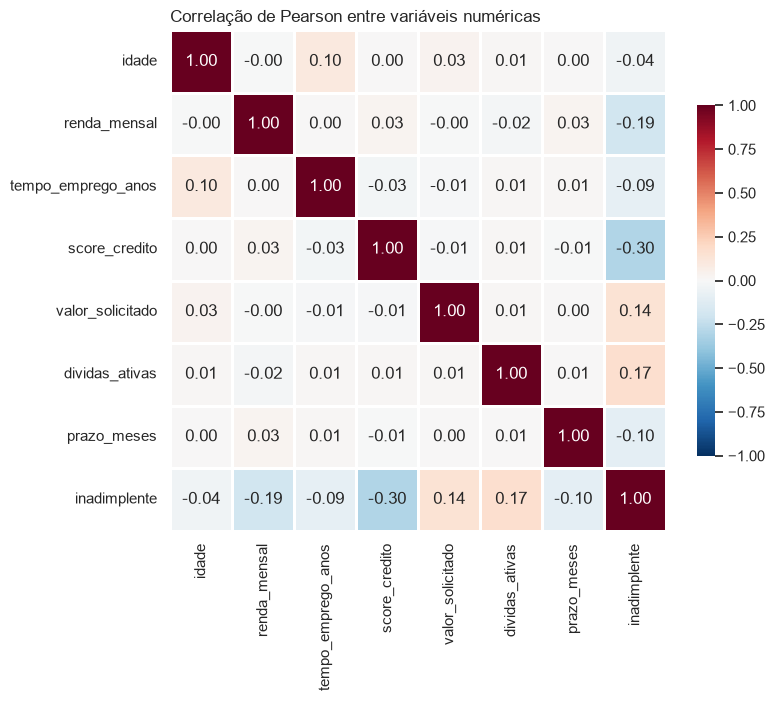

In [35]:
corr = prata[numericas + ["prazo_meses", "inadimplente"]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação de Pearson entre variáveis numéricas", loc="left")
salvar(fig, "05_correlacao")
plt.show()


**Leitura:**
- **Sem redundância:** nenhum par de variáveis explicativas passa de 0,7. O maior é idade × tempo de emprego (0,10). Cada variável traz informação diferente, e **não há multicolinearidade**.
- **Com a inadimplência**, a ordem confirma os gráficos anteriores: **score (-0,30)**, renda (-0,19), dívidas (+0,17) e valor (+0,14). Para uma variável 0/1, correlações nessa faixa são esperadas; o que importa é a ordem.
- **Valor × prazo = 0,00:** valores altos não vêm necessariamente com prazos longos. A **parcela** varia muito entre propostas e não é medida por nenhuma variável atual, o que reforça a hipótese da seção 4.3.


### 4.6 Principais achados da análise exploratória

| # | Achado | Evidência |
|---|---|---|
| 1 | **Score de crédito é o sinal individual mais forte** | Inadimplência cai de 56% (Q1) para 16% (Q5); correlação -0,30 |
| 2 | **Renda mais baixa, mais risco** | De 53% (Q1) para 21% (Q5) |
| 3 | **Mais dívidas ativas, mais risco** | De 27% (0 dívidas) para 61% (7 dívidas); p < 0,0001 |
| 4 | **Prazos curtos têm mais inadimplência** (contraintuitivo) | 54% em 6 meses contra 28% em 36 meses; p < 0,0001 |
| 5 | **Valor solicitado maior, mais risco** | De 27% (Q1) para 45% (Q5) |
| 6 | **Estado, escolaridade e finalidade não mostram associação** | Qui-quadrado: p = 0,60, 0,23 e 0,54 |

**Hipótese para a próxima seção:** os achados 2, 4 e 5 podem ser faces de um mesmo fenômeno: o **peso da parcela na renda**. Vamos criar essa variável e testá-la.

*Ressalva:* os resultados mostram **associação**, não causalidade.


## 5. Engenharia de atributos (prata → 🥇 ouro)

A análise exploratória mostrou um efeito curioso: **prazos curtos têm mais inadimplência**. Hipótese de negócio: com o mesmo valor, um prazo curto gera uma **parcela maior**, que pesa mais no orçamento. Nenhuma variável original mede esse "peso no orçamento". Vamos criá-la, junto com duas alternativas para comparação.

| Variável derivada | Como é construída | O que representa | Hipótese de relação com o risco |
|---|---|---|---|
| `parcela_estimada` | `valor_solicitado / prazo_meses` | Parcela mensal aproximada, **sem juros** | Parcelas maiores são mais difíceis de pagar |
| `comprometimento_renda` | `parcela_estimada / renda_mensal` | **Fração da renda** comprometida com a parcela | Quanto maior o comprometimento, menor a folga e maior o risco |
| `valor_sobre_renda` | `valor_solicitado / renda_mensal` | Quantas rendas mensais vale o empréstimo | Empréstimos grandes para a renda são mais arriscados |

> 🧭 **Decisão: ignorar os juros.** Não temos a taxa de juros na base. A parcela estimada é uma **aproximação**, mas preserva a ordem: quem pede mais em menos tempo tem parcela maior.
>
> 🧭 **Decisão: só transformações linha a linha na camada ouro.** Cada variável nova usa apenas dados **da própria linha**, sem médias ou estatísticas da base. Por isso pode ser calculada antes da divisão treino/teste **sem vazamento de dados**.


In [39]:
def criar_atributos(df: pd.DataFrame) -> pd.DataFrame:
    # Cria as variáveis derivadas (transformações determinísticas, linha a linha)
    df = df.copy()
    df["parcela_estimada"] = df["valor_solicitado"] / df["prazo_meses"]
    df["comprometimento_renda"] = df["parcela_estimada"] / df["renda_mensal"]
    df["valor_sobre_renda"] = df["valor_solicitado"] / df["renda_mensal"]
    return df


ouro = criar_atributos(prata)
ouro[["valor_solicitado", "prazo_meses", "renda_mensal", "parcela_estimada",
      "comprometimento_renda", "valor_sobre_renda"]].describe().T


,count,mean,std,min,25%,50%,75%,max
valor_solicitado,"4,981.000","14,260.293","8,267.027","1,721.480","8,466.240","12,363.960","17,763.210","50,000.000"
prazo_meses,"4,981.000",29.913,15.487,6.000,18.000,24.000,36.000,60.000
renda_mensal,"4,971.000","5,238.841","3,968.128",900.000,"2,704.045","4,153.690","6,465.970","44,814.190"
parcela_estimada,"4,981.000",685.923,694.775,44.681,270.384,458.843,832.919,"8,333.333"
comprometimento_renda,"4,971.000",0.200,0.267,0.004,0.056,0.111,0.233,4.024
valor_sobre_renda,"4,971.000",4.128,3.920,0.130,1.666,2.958,5.255,44.070


**Leitura:**
- **Mediana de `comprometimento_renda` = 0,11:** metade das propostas compromete até 11% da renda com a parcela. A média (0,20) é maior porque é puxada pelos casos extremos.
- **Máximo = 4,02:** há propostas em que a parcela supera a renda. **Não é erro de dado**: são propostas reais com valor alto demais para a renda. Por isso **não são removidas**: são justamente os casos de maior risco, e o modelo precisa aprender com eles. Limitar o comprometimento é uma decisão de **política de crédito**, retomada na conclusão.
- `comprometimento_renda` e `valor_sobre_renda` têm 10 ausentes, herdados das rendas inválidas (P5). Serão imputados no pipeline.


### 5.1 As novas variáveis ajudam a separar as classes?

Para medir o **poder de separação individual** de cada variável, usamos a **AUC** (área sob a curva ROC): a chance de, sorteando um inadimplente e um adimplente, a variável dar ao inadimplente o valor mais "arriscado".
- **AUC de 0,5:** a variável não separa as classes; é o mesmo que sortear.
- **AUC de 1,0:** separação perfeita.

Valores abaixo de 0,5 indicam relação **inversa** (ex.: score alto = risco baixo). Nesse caso, mostramos `1 − AUC` para facilitar a comparação.


In [40]:
from sklearn.metrics import roc_auc_score

candidatas = ["score_credito", "comprometimento_renda", "renda_mensal", "valor_sobre_renda", "dividas_ativas",
              "parcela_estimada", "prazo_meses", "valor_solicitado", "tempo_emprego_anos", "idade"]
linhas = []
for col in candidatas:
    validos = ouro[col].notna()
    auc = roc_auc_score(ouro.loc[validos, "inadimplente"], ouro.loc[validos, col])
    linhas.append({"variável": col, "AUC individual": max(auc, 1 - auc),
                   "direção": "↑ valor, ↑ risco" if auc >= 0.5 else "↑ valor, ↓ risco",
                   "nova?": "✨" if col in ("parcela_estimada", "comprometimento_renda", "valor_sobre_renda") else ""})
auc_individual = pd.DataFrame(linhas).sort_values("AUC individual", ascending=False).set_index("variável")
auc_individual.round(3)


,AUC individual,direção,nova?
variável,,,
score_credito,0.682,"↑ valor, ↓ risco",
comprometimento_renda,0.667,"↑ valor, ↑ risco",✨
valor_sobre_renda,0.664,"↑ valor, ↑ risco",✨
renda_mensal,0.641,"↑ valor, ↓ risco",
parcela_estimada,0.606,"↑ valor, ↑ risco",✨
dividas_ativas,0.596,"↑ valor, ↑ risco",
valor_solicitado,0.584,"↑ valor, ↑ risco",
prazo_meses,0.565,"↑ valor, ↓ risco",
tempo_emprego_anos,0.553,"↑ valor, ↓ risco",


**Leitura:** ✅ hipótese confirmada. `comprometimento_renda` é a **2ª variável mais discriminante** (AUC 0,667), logo atrás do score (0,682) e **à frente das três variáveis que combina**: renda (0,641), valor (0,584) e prazo (0,565). A combinação captura algo que nenhuma delas mede sozinha. Já `parcela_estimada` (0,606) é bem mais fraca, porque ignora a renda: uma mesma parcela pesa diferente para quem ganha mais ou menos.


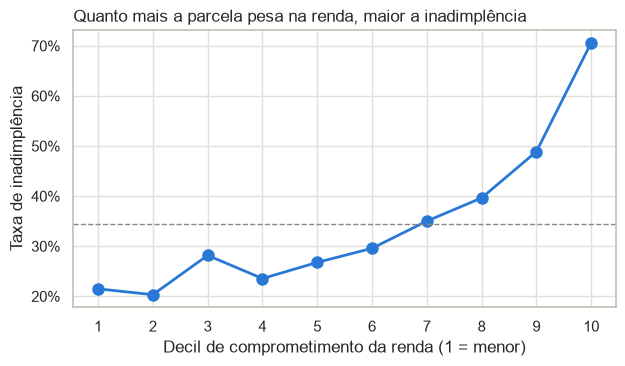

In [41]:
fig, ax = plt.subplots(figsize=(7, 3.6))
faixas = pd.qcut(ouro["comprometimento_renda"], 10)
t = ouro.groupby(faixas, observed=True)["inadimplente"].mean()
ax.plot(range(1, 11), t.values, color=AZUL, lw=2, marker="o", ms=8)
ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil de comprometimento da renda (1 = menor)")
ax.set_ylabel("Taxa de inadimplência")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Quanto mais a parcela pesa na renda, maior a inadimplência", loc="left")
salvar(fig, "06_comprometimento_renda")
plt.show()


In [42]:
# Valores do gráfico: taxa de inadimplência e faixa de comprometimento em cada decil
pd.DataFrame({
    "comprometimento": [f"{f.left:.0%} a {f.right:.0%}" for f in t.index],
    "taxa": t.map("{:.0%}".format).values,
}, index=[f"D{i}" for i in range(1, 11)])


,comprometimento,taxa
D1,0% a 3%,21%
D2,3% a 5%,20%
D3,5% a 7%,28%
D4,7% a 9%,24%
D5,9% a 11%,27%
D6,11% a 15%,30%
D7,15% a 20%,35%
D8,20% a 28%,40%
D9,28% a 45%,49%
D10,45% a 402%,71%


**Leitura:** a relação é **clara e crescente**. A inadimplência vai de **21%** no decil de menor comprometimento (D1, até ~3% da renda) para **71%** no decil mais alto (D10, parcela de **45% da renda ou mais**). Até ~15% de comprometimento (D6), a taxa fica abaixo da média; a partir do D7, cruza a média e acelera.

**Isso explica o "paradoxo do prazo"** (seção 4.3): prazos curtos não são arriscados por si mesmos. Eles **geram parcelas maiores**, e é o **peso da parcela na renda** que eleva o risco.

*Observação:* o limite superior do D10 (402%) é o maior valor da base. O `qcut` cria faixas com o mesmo número de propostas, então o último decil vai até o máximo, e reúne poucos casos muito espalhados.


In [43]:
print("Correlação entre as variáveis derivadas e as originais:")
ouro[["comprometimento_renda", "valor_sobre_renda", "parcela_estimada", "valor_solicitado", "renda_mensal"]].corr().round(2)


Correlação entre as variáveis derivadas e as originais:


,comprometimento_renda,valor_sobre_renda,parcela_estimada,valor_solicitado,renda_mensal
comprometimento_renda,1.000,0.690,0.750,0.410,-0.340
valor_sobre_renda,0.690,1.000,0.340,0.590,-0.470
parcela_estimada,0.750,0.340,1.000,0.550,-0.020
valor_solicitado,0.410,0.590,0.550,1.000,-0.000
renda_mensal,-0.340,-0.470,-0.020,-0.000,1.000


In [44]:
OURO.parent.mkdir(parents=True, exist_ok=True)
ouro.to_parquet(OURO, index=False)
print(f"Camada ouro salva em {OURO.relative_to(RAIZ)}: {ouro.shape[0]:,} linhas × {ouro.shape[1]} colunas")


Camada ouro salva em data\gold\credito_modelagem.parquet: 4,981 linhas × 14 colunas
